# Simple Feature Exploration

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from pathlib import Path

In [5]:
metadata_full = pd.read_csv("./sample_images/metadata.csv", index_col=0)
cols_to_keep = ["image_id", "width", "height", "file_name", "common_name", "supercategory"]
metadata = metadata_full[cols_to_keep].copy()
metadata.head()

,image_id,width,height,file_name,common_name,supercategory
0,2775952,500,375,val/02988_Animalia_Chordata_Amphibia_Anura_Hyl...,Pine Woods Tree Frog,Amphibians
1,2691604,500,281,val/03091_Animalia_Chordata_Amphibia_Caudata_P...,White-spotted Slimy Salamander,Amphibians
2,2692530,500,375,val/03081_Animalia_Chordata_Amphibia_Caudata_P...,Ensatina,Amphibians
3,2704304,500,244,val/03082_Animalia_Chordata_Amphibia_Caudata_P...,Northern Two-lined Salamander,Amphibians
4,2764140,500,333,val/02976_Animalia_Chordata_Amphibia_Anura_Dic...,Alpine Cricket Frog,Amphibians


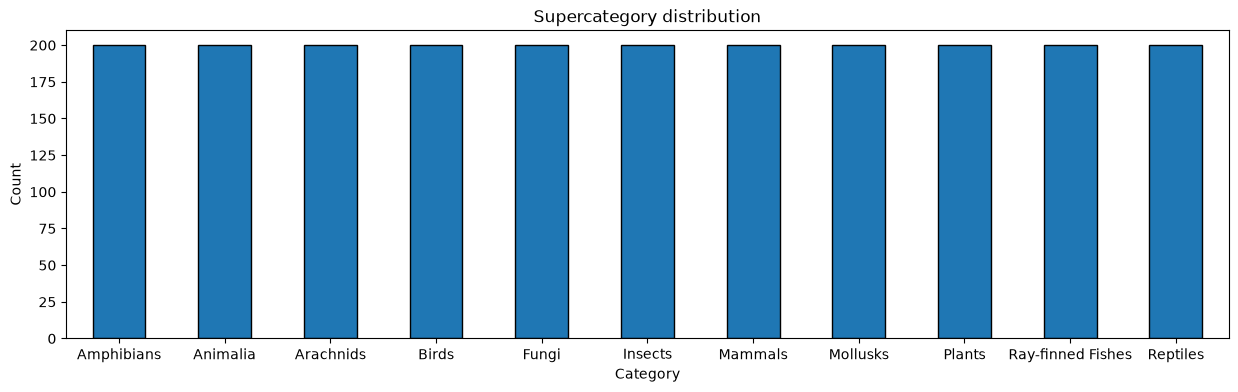

In [8]:
plt.figure(figsize=(15,4))
metadata["supercategory"].value_counts().plot(kind='bar', edgecolor='black', rot=0)
plt.title("Supercategory distribution")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

In [ ]:
sample_image_ids = metadata.groupby("supercategory")["image_id"].sample(n=1, random_state=1).tolist()
sample_df = metadata[metadata["image_id"].isin(sample_image_ids)]
sample_df

,image_id,width,height,file_name,common_name,supercategory
58,2776774,500,375,val/02992_Animalia_Chordata_Amphibia_Anura_Hyl...,Mediterranean Tree Frog,Amphibians
281,2690111,500,375,val/05207_Animalia_Echinodermata_Asteroidea_Va...,Leather Star,Animalia
465,2744209,500,466,val/00138_Animalia_Arthropoda_Arachnida_Ixodid...,Pacific Coast Tick,Arachnids
796,2748834,500,333,val/04203_Animalia_Chordata_Aves_Passeriformes...,Wrentit,Birds
816,2726931,500,406,val/05585_Fungi_Basidiomycota_Agaricomycetes_A...,shaggy pholiota,Fungi
1016,2708827,500,375,val/02061_Animalia_Arthropoda_Insecta_Lepidopt...,Mottled Emigrant,Insects
1222,2701525,500,375,val/04615_Animalia_Chordata_Mammalia_Artiodact...,Humpback Whale,Mammals
1411,2736606,500,375,val/05259_Animalia_Mollusca_Gastropoda_Archita...,Channeled Applesnail,Mollusks
1772,2748277,281,500,val/05884_Plantae_Tracheophyta_Liliopsida_Aspa...,harvest brodiaea,Plants
1826,2733628,500,408,val/02918_Animalia_Chordata_Actinopterygii_Syn...,Pot-bellied Seahorse,Ray-finned Fishes


In [18]:
data_dir = Path("./sample_images/images")
imgs = [np.array(Image.open(data_dir / path)) for path in sample_df["file_name"].tolist()]

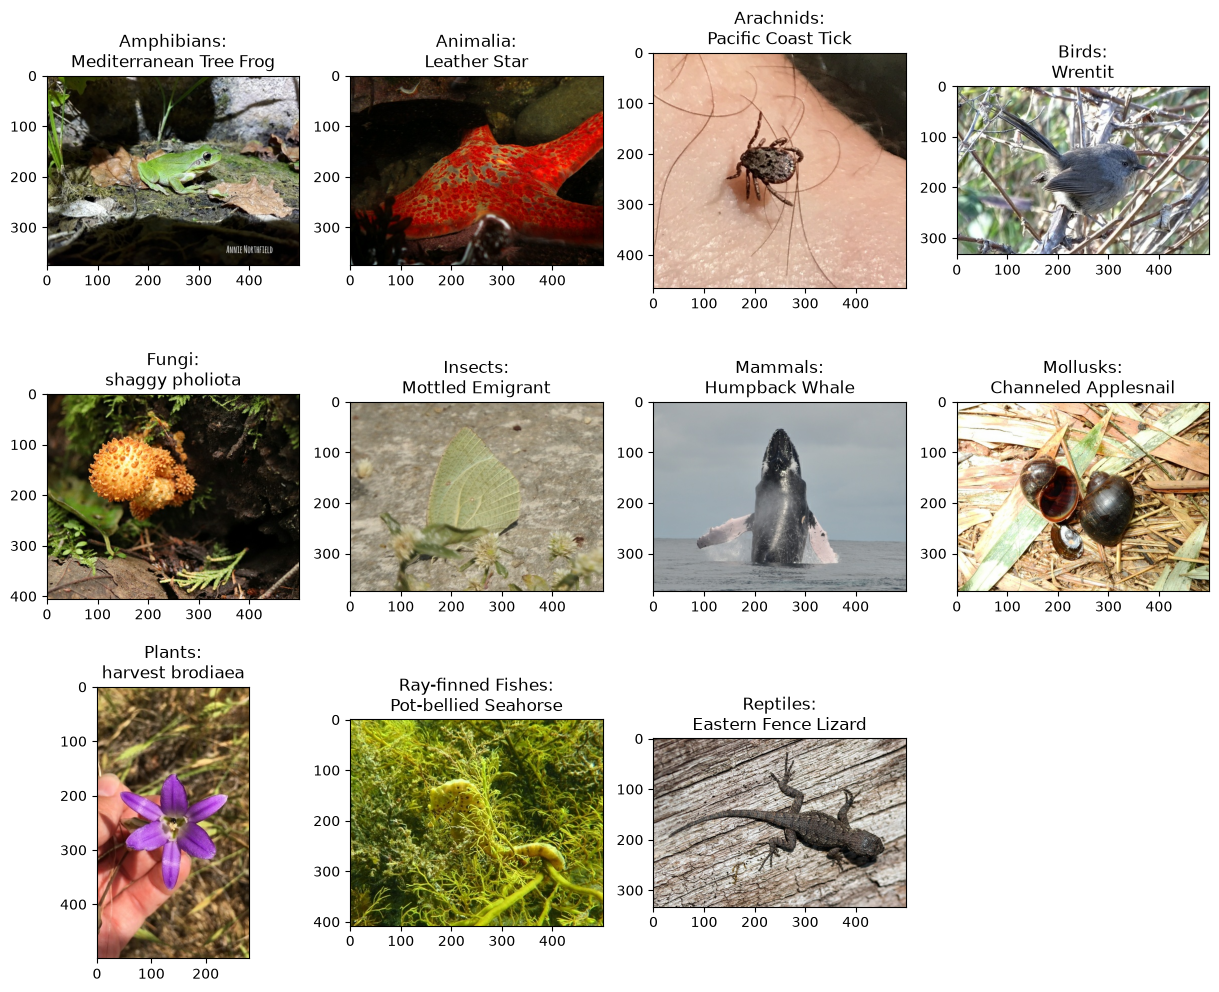

In [26]:
fig, axs = plt.subplots(ncols=4, nrows=3, figsize=(15,12))
axes = axs.flatten()
for i in range(len(imgs)):
    axes[i].imshow(imgs[i])
    axes[i].set_title(f"{sample_df["supercategory"].tolist()[i]}:\n{sample_df["common_name"].tolist()[i]}")

axes[-1].set_visible(False)

# Color Histogram

In [28]:
def get_color_hist(img):
    colors = ('red', 'green', 'blue')
    result = {}
    for channel_id, color in enumerate(colors):
        hist, bin_edges = np.histogram(img[:, :, channel_id], bins=256, range=(0, 256))
        result[color]=hist
    result["bin_edges"]=bin_edges
    return result

In [34]:
categories = set(metadata['supercategory'].tolist())
hists_by_cat = {}
for cat in categories:
    imgs = metadata[metadata['supercategory']==cat]["image_id"].tolist()
    color_hists = {}
    for id in imgs:
        im_path = metadata[metadata["image_id"]==id]["file_name"].tolist()[0]
        img = np.array(Image.open(data_dir / im_path))
        single_hist = get_color_hist(img)

        if color_hists:
            color_hists['red'] + single_hist['red']
            color_hists['green'] + single_hist['green']
            color_hists['blue'] + single_hist['blue']
        else:
            color_hists = single_hist
    hists_by_cat[cat]=color_hists


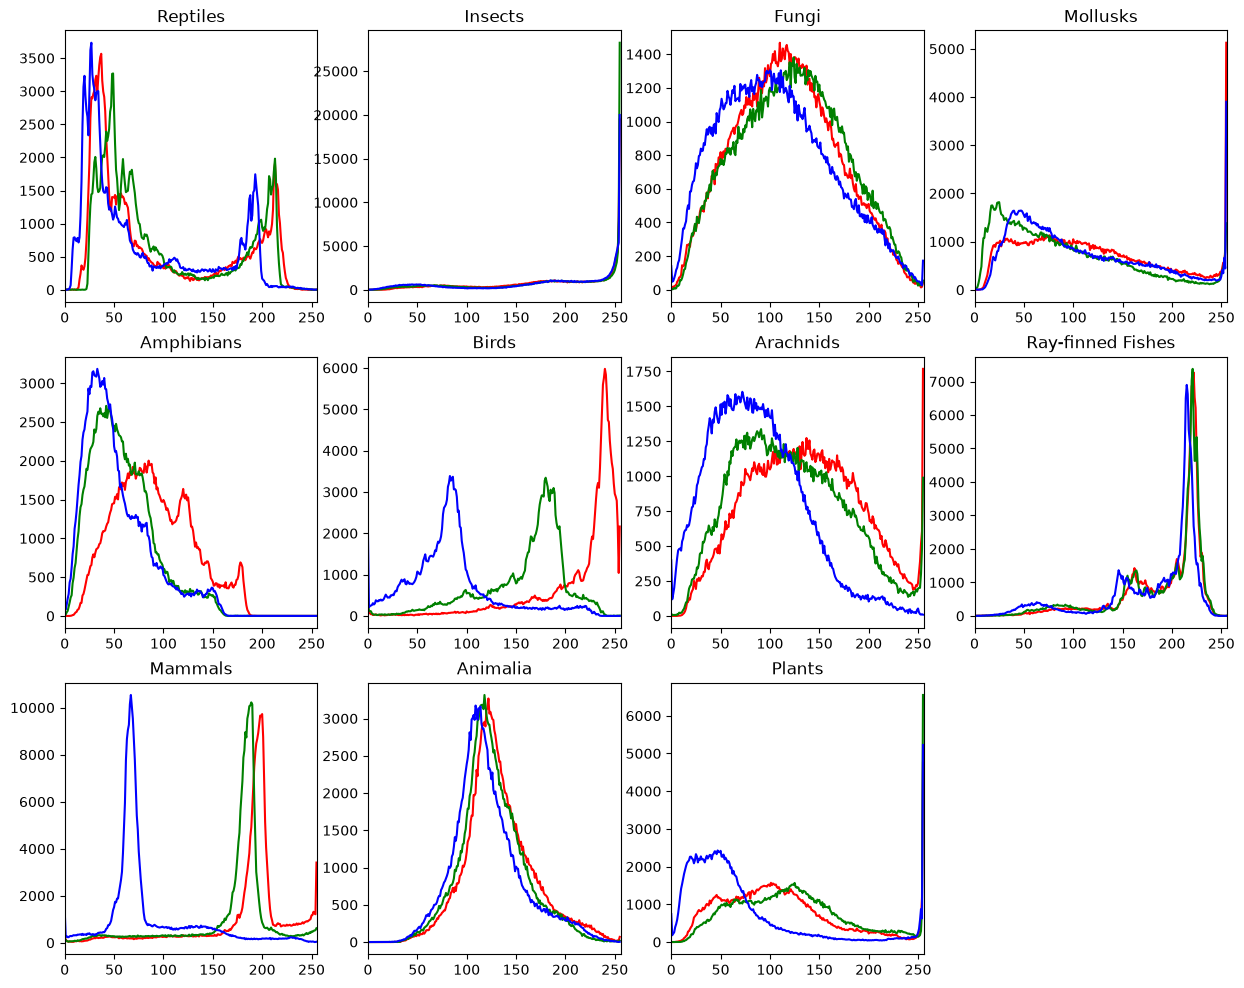

In [35]:
fig, axs = plt.subplots(ncols=4, nrows=3, figsize=(15,12))
axes = axs.flatten()
for i, cat in enumerate(categories):
    bin_edges = hists_by_cat[cat]["bin_edges"]
    for color in ["red", "green", "blue"]:
        hist = hists_by_cat[cat][color]
        axes[i].plot(bin_edges[:-1], hist, color=color)
        axes[i].set_xlim([0,256])
        axes[i].set_title(cat)

axes[-1].set_visible(False)
plt.show()

# Rotation Invariant LBP (local binary pattern) - for textures